# Imoprt and Install Libraries 

In [ ]:
pip install matplotlib

In [ ]:
pip install statsmodels

In [ ]:
pip install scikit-learn

In [7]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import matplotlib.pyplot as plt


# Import dataset

In [8]:
df = pd.read_csv(r"C:\Users\bilal\Desktop\gitRepo\Locked\LockedItems\Datasets\Span_new.csv")

# Exploratory data analysis

In [9]:
df.tail()

,Unnamed: 0,ID,make,model,months_old,power,gear,fuel_type,kms,price,age
92380,93986,38173,Opel,Astra,275,52,manual,gasoline,134700,350,1995
92381,93987,57303,Volkswagen,Polo,232,37,manual,gasoline,67762,350,1998
92382,93988,14541,Bmw,320,186,125,manual,gasoline,200000,300,2002
92383,93989,103604,Seat,Toledo,276,66,manual,gasoline,196000,300,1995
92384,93990,99672,Seat,Cordoba,232,81,manual,diesel,150000,200,1998


In [10]:
df.head()

,Unnamed: 0,ID,make,model,months_old,power,gear,fuel_type,kms,price,age
0,0,97860,Porsche,911,240,210,manual,gasoline,202000,999999,1998
1,1,27821,Ford,Mustang,54,487,manual,gasoline,30000,685000,2013
2,2,97801,Porsche,911,358,220,manual,gasoline,56300,555555,1988
3,3,98251,Porsche,911,14,368,manual,gasoline,2800,470000,2016
4,4,98250,Porsche,911,3,515,unknown,gasoline,10,450000,2017


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 92385 entries, 0 to 92384
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  92385 non-null  int64
 1   ID          92385 non-null  int64
 2   make        92385 non-null  str  
 3   model       92385 non-null  str  
 4   months_old  92385 non-null  int64
 5   power       92385 non-null  int64
 6   gear        92385 non-null  str  
 7   fuel_type   92385 non-null  str  
 8   kms         92385 non-null  int64
 9   price       92385 non-null  int64
 10  age         92385 non-null  int64
dtypes: int64(7), str(4)
memory usage: 9.9 MB


In [12]:
df.columns

Index(['Unnamed: 0', 'ID', 'make', 'model', 'months_old', 'power', 'gear',
       'fuel_type', 'kms', 'price', 'age'],
      dtype='str')

In [13]:
df.isnull().sum()

Unnamed: 0    0
ID            0
make          0
model         0
months_old    0
power         0
gear          0
fuel_type     0
kms           0
price         0
age           0
dtype: int64

In [8]:
df.describe(include="all")

,Unnamed: 0,ID,make,model,months_old,power,gear,fuel_type,kms,price,age
count,92385.000000,92385.000000,92385,92385,92385.000000,92385.000000,92385,92385,92385.000000,92385.000000,92385.000000
unique,NaN,NaN,36,247,NaN,NaN,4,6,NaN,NaN,NaN
top,NaN,NaN,Bmw,Golf,NaN,NaN,manual,diesel,NaN,NaN,NaN
freq,NaN,NaN,10546,2433,NaN,NaN,66584,70699,NaN,NaN,NaN
mean,47257.588948,55127.578644,NaN,NaN,63.781436,99.817936,NaN,NaN,83161.963068,16511.689203,2012.238437
std,27180.244200,33146.298945,NaN,NaN,56.871827,42.749383,NaN,NaN,75231.338722,15568.470902,4.751661
min,0.000000,25.000000,NaN,NaN,1.000000,0.000000,NaN,NaN,1.000000,200.000000,1987.000000
25%,23696.000000,25434.000000,NaN,NaN,17.000000,77.000000,NaN,NaN,18616.000000,8500.000000,2009.000000
50%,47461.000000,53909.000000,NaN,NaN,46.000000,88.000000,NaN,NaN,66687.000000,13345.000000,2014.000000
75%,70849.000000,83611.000000,NaN,NaN,97.000000,110.000000,NaN,NaN,129000.000000,19990.000000,2016.000000


In [9]:
df.gear.value_counts()

gear
manual            66584
automatic         24275
unknown            1234
semi-automatic      292
Name: count, dtype: int64

In [10]:
df.columns

Index(['Unnamed: 0', 'ID', 'make', 'model', 'months_old', 'power', 'gear',
       'fuel_type', 'kms', 'price', 'age'],
      dtype='str')

In [11]:
df.drop([3,4,5,6,7], axis = 0, inplace= True)

In [12]:
len(df.columns)

11

In [13]:
df.info

<bound method DataFrame.info of        Unnamed: 0      ID        make        model  months_old  power  \
0               0   97860     Porsche          911         240    210   
1               1   27821        Ford      Mustang          54    487   
2               2   97801     Porsche          911         358    220   
8               8   62403     Bentley  Continental           5    522   
9               9   62402     Bentley  Continental          14    522   
...           ...     ...         ...          ...         ...    ...   
92380       93986   38173        Opel        Astra         275     52   
92381       93987   57303  Volkswagen         Polo         232     37   
92382       93988   14541         Bmw          320         186    125   
92383       93989  103604        Seat       Toledo         276     66   
92384       93990   99672        Seat      Cordoba         232     81   

            gear fuel_type     kms   price   age  
0         manual  gasoline  202000  9999

In [21]:
df.head(10)

,Unnamed: 0,ID,make,model,months_old,power,gear,fuel_type,kms,price,age
0,0,97860,Porsche,911,240,210,manual,gasoline,202000,999999,1998
1,1,27821,Ford,Mustang,54,487,manual,gasoline,30000,685000,2013
2,2,97801,Porsche,911,358,220,manual,gasoline,56300,555555,1988
8,8,62403,Bentley,Continental,5,522,automatic,gasoline,1200,302900,2017
9,9,62402,Bentley,Continental,14,522,automatic,gasoline,17900,289700,2016
10,10,62401,Bentley,Continental,7,522,automatic,gasoline,9900,284900,2017
11,11,62294,Bentley,Continental,8,388,automatic,gasoline,2500,263724,2017
12,12,98221,Porsche,911,24,368,automatic,gasoline,1574,259900,2016
13,13,98249,Porsche,911,6,427,automatic,gasoline,620,254900,2017
14,15,98191,Porsche,911,16,368,automatic,gasoline,5100,245900,2016


In [22]:
df["fuel_type"].value_counts()

fuel_type
diesel      70699
gasoline    21023
hybrid        470
electric       92
unknown        53
LPG            43
Name: count, dtype: int64

In [23]:
df.gear.value_counts()

gear
manual            66581
automatic         24274
unknown            1233
semi-automatic      292
Name: count, dtype: int64

In [24]:
df['Unnamed: 0']

0            0
1            1
2            2
8            8
9            9
         ...  
92380    93986
92381    93987
92382    93988
92383    93989
92384    93990
Name: Unnamed: 0, Length: 92380, dtype: int64

In [6]:
df.months_old

NameError: name 'df' is not defined

In [2]:
df.model.value_counts(`0)

SyntaxError: invalid syntax (3473541833.py, line 1)

In [27]:
df.kms

0        202000
1         30000
2         56300
8          1200
9         17900
          ...  
92380    134700
92381     67762
92382    200000
92383    196000
92384    150000
Name: kms, Length: 92380, dtype: int64

# Pre process Data

In [28]:
# Convert Unnamed into the index

df.rename({"Unnamed: 0": "Index"}, axis= 1, inplace= True)

In [29]:
df.columns

Index(['Index', 'ID', 'make', 'model', 'months_old', 'power', 'gear',
       'fuel_type', 'kms', 'price', 'age'],
      dtype='str')

In [30]:
df.rename({"age": "Year"}, axis = 1, inplace= True)

In [31]:
df.columns

Index(['Index', 'ID', 'make', 'model', 'months_old', 'power', 'gear',
       'fuel_type', 'kms', 'price', 'Year'],
      dtype='str')

# IV and DV

In [33]:
dv = df["price"]
dv

0        999999
1        685000
2        555555
8        302900
9        289700
          ...  
92380       350
92381       350
92382       300
92383       300
92384       200
Name: price, Length: 92380, dtype: int64

In [52]:
iv = df[["power", "Year"]]
# iv = df[["power", "Year", "kms", "months_old"]]
iv

,power,Year
0,210,1998
1,487,2013
2,220,1988
8,522,2017
9,522,2016
...,...,...
92380,52,1995
92381,37,1998
92382,125,2002
92383,66,1995


# Split Data

In [53]:
x_train, x_test, y_train, y_test = train_test_split(iv, dv, test_size=0.2)

In [54]:
x_train.shape

(73904, 2)

In [55]:
x_test.shape

(18476, 2)

In [56]:
y_train.shape

(73904,)

In [57]:
y_test.shape

(18476,)

# Regression/ model Train

In [58]:
# x_train = sm.add_constant(x_train) # This will add the constant to the model (Try removing it and see how R2 changes )
# x_test = sm.add_constant(x_test)
regression_model = sm.OLS(y_train, x_train)

In [59]:
results = regression_model.fit()

In [60]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                  price   R-squared (uncentered):                   0.742
Model:                            OLS   Adj. R-squared (uncentered):              0.742
Method:                 Least Squares   F-statistic:                          1.060e+05
Date:                Fri, 20 Nov 2026   Prob (F-statistic):                        0.00
Time:                        19:38:49   Log-Likelihood:                     -7.9599e+05
No. Observations:               73904   AIC:                                  1.592e+06
Df Residuals:                   73902   BIC:                                  1.592e+06
Df Model:                           2                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
power        242.8483      0.987    245.933      0.000     240.913     244.784
Year          -3.8437      0.053    -72.126      0.000      -3.948      -3.739
==============================================================================
Omnibus:                   134765.588   Durbin-Watson:                   1.997
Prob(Omnibus):                  0.000   Jarque-Bera (JB):       1983946469.445
Skew:                          12.543   Prob(JB):                         0.00
Kurtosis:                     805.277   Cond. No.                         47.0
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

# Interpretation of OLS Regression Results

OLS (Ordinary Least Squares) is a statistical method used to estimate the relationship between independent variables (features) and a dependent variable (target).

In this model, we are predicting vehicle prices using two independent variables:

- Dependent Variable (Y): price
- Independent Variables (X): power, Year

## 1. Overall Model Information

**Dependent Variable: price**

This is the variable we want to predict using our regression model.

**Model: OLS**

OLS stands for Ordinary Least Squares. It finds the best-fitting regression coefficients by minimizing the sum of squared differences between actual and predicted values.

**Method: Least Squares**

The model minimizes the squared prediction errors (residuals).

**No. Observations: 73,904**

The model was trained using 73,904 records.

**Df Model: 2**

The model contains two independent variables: power and Year.

**Df Residuals: 73,902**

These are the residual degrees of freedom. Since the model has no intercept, the calculation is:

73,904 - 2 = 73,902.

**Covariance Type: nonrobust**

The model uses conventional standard errors, which assume the error variance is constant. If heteroscedasticity exists, these standard errors and their associated statistical tests may be unreliable.

## 2. R-Squared (Uncentered): 0.742

R-squared measures how well the regression model fits the dependent variable.

For a standard regression model with an intercept, R-squared tells us how much of the variance in the target variable is explained by the model.

Example:

If R-squared = 0.80 (80%), it means:
- 80% of the variance in the target variable is explained by the model.
- 20% of the variance remains unexplained by the model.

**Important:** Our output specifically reports Uncentered R-squared = 0.742.

This is calculated relative to zero rather than the mean of the target variable. Therefore, we should not directly interpret 0.742 as 74.2% of the variance explained in the conventional sense.

## 3. Adjusted R-Squared (Uncentered): 0.742

Adjusted R-squared considers the number of independent variables used in the model.

It penalizes unnecessary features that do not contribute meaningfully to the model.

It is useful when comparing models with different numbers of independent variables.

Our adjusted uncentered R-squared is 0.742.

## 4. F-Statistic: 1.060e+05

The F-statistic evaluates whether the independent variables collectively have a statistically significant relationship with the dependent variable.

Our F-statistic is:

106,000 approximately.

A larger F-statistic generally indicates stronger evidence against the null hypothesis.

The null hypothesis assumes that all independent variable coefficients are zero.

H0: β1 = β2 = 0

The alternative hypothesis is that at least one coefficient is nonzero.

## 5. Prob (F-Statistic): 0.00

This is the p-value associated with the overall F-test.

Our p-value is extremely small (displayed as 0.00).

Since:

p < 0.05

We reject the null hypothesis.

**Interpretation:** There is strong statistical evidence that the independent variables collectively have a relationship with vehicle price.

## 6. Regression Coefficients

The coefficient tells us how much the predicted target variable changes when an independent variable increases by one unit, while keeping other variables constant.

Our regression coefficients are:

### A. Power: 242.8483

The coefficient of power is positive.

Interpretation:

For every one-unit increase in vehicle power, the predicted vehicle price increases by approximately 242.85 units, assuming Year remains constant.

Example:

If power increases by 10 units:

10 × 242.8483 = 2428.483

The predicted vehicle price increases by approximately 2428.48 units.

Conclusion:

Power has a positive relationship with vehicle price.

### B. Year: -3.8437

The coefficient of Year is negative.

Interpretation:

For every one-unit increase in Year, the predicted vehicle price decreases by approximately 3.84 units, assuming power remains constant.

Example:

If Year increases by 5 units:

5 × (-3.8437) = -19.2185

The predicted vehicle price decreases by approximately 19.22 units.

Conclusion:

Year has a negative conditional relationship with vehicle price in this fitted model.

A negative coefficient does not necessarily mean newer vehicles are cheaper in general. It describes the relationship estimated by this particular model, holding power constant.

## 7. Standard Error

Standard Error measures the uncertainty associated with an estimated regression coefficient.

Our results:

- Power: 0.987
- Year: 0.053

A smaller standard error generally indicates that the coefficient has been estimated more precisely.

For example:

Power:
- Coefficient = 242.8483
- Standard Error = 0.987

This indicates that the estimated power coefficient has relatively low statistical uncertainty under the model assumptions.

## 8. T-Statistic

The t-statistic measures how far an estimated coefficient is from zero relative to its standard error.

Formula:

t = Coefficient / Standard Error

Our results:

- Power: 245.933
- Year: -72.126

Interpretation:

A large positive t-statistic indicates evidence of a positive coefficient.

A large negative t-statistic indicates evidence of a negative coefficient.

A t-statistic close to zero indicates weaker evidence that the coefficient differs from zero.

Both variables have large absolute t-statistics, suggesting strong statistical evidence that their coefficients are different from zero.

## 9. P-value (P greater than |t|)

The p-value tests whether an individual regression coefficient is statistically different from zero.

The null hypothesis is:

H0: β = 0

The alternative hypothesis is:

H1: β ≠ 0

Our results:

- Power: 0.000
- Year: 0.000

Since both p-values are below 0.05, both variables are statistically significant at the 5% significance level.

Important:

A p-value displayed as 0.000 does not mean the actual p-value is exactly zero. It means the value is extremely small and rounded for display.

Statistical significance does not automatically mean that a variable has a large practical impact.

## 10. Confidence Interval (95%)

A confidence interval provides a range of plausible values for the true regression coefficient.

Our results:

Power:
- Lower limit: 240.913
- Upper limit: 244.784

Year:
- Lower limit: -3.948
- Upper limit: -3.739

Interpretation:

The 95% confidence interval for power is between 240.913 and 244.784.

The 95% confidence interval for Year is between -3.948 and -3.739.

Since neither interval contains zero, both coefficients are statistically significant at the 5% level under the model assumptions.

## 11. Model Diagnostics

These statistics help us evaluate whether the assumptions of the regression model are reasonable.

### A. Omnibus: 134765.588

The Omnibus test checks whether the regression residuals follow a normal distribution.

A large value suggests that the residual distribution may differ substantially from a normal distribution.

Our value is very high, indicating a potential normality problem.

### B. Prob (Omnibus): 0.000

This is the p-value of the Omnibus test.

Since the p-value is below 0.05, we reject the null hypothesis of normally distributed residuals.

### C. Jarque-Bera (JB): 1983946469.445

The Jarque-Bera test checks residual normality using skewness and kurtosis.

A very large value suggests that the residual distribution differs substantially from a normal distribution.

Our value indicates a significant potential normality issue.

### D. Prob (JB): 0.00

The p-value is extremely small.

Therefore, we reject the null hypothesis that the residuals follow a normal distribution.

### E. Skewness: 12.543

Skewness measures the asymmetry of a distribution.

Interpretation:

- Skewness = 0: Symmetrical distribution.
- Positive skewness: Longer right tail.
- Negative skewness: Longer left tail.

Our skewness is 12.543, indicating extreme positive skewness.

This suggests that the residual distribution has a long right tail and may contain extreme positive residuals.

### F. Kurtosis: 805.277

Kurtosis measures the heaviness of the tails of a distribution.

For a normal distribution, kurtosis is approximately 3.

Our kurtosis is 805.277, which is extremely high.

This indicates unusually heavy tails and potentially extreme outliers in the residual distribution.

### G. Durbin-Watson: 1.997

The Durbin-Watson statistic checks for first-order autocorrelation in regression residuals.

Its values generally range from 0 to 4.

Interpretation:

- Near 0: Positive autocorrelation.
- Near 2: Little or no first-order autocorrelation.
- Near 4: Negative autocorrelation.

Our value is 1.997, which is very close to 2.

This indicates little evidence of first-order residual autocorrelation.

### H. Condition Number: 47.0

The condition number helps identify potential numerical instability and multicollinearity.

A high condition number can indicate that independent variables are highly correlated or have very different numerical scales.

Our condition number is 47.0.

This does not by itself prove that multicollinearity exists. We can investigate further using a correlation matrix and Variance Inflation Factor (VIF).

## 12. Overall Conclusion

Our OLS regression model uses two independent variables, power and Year, to predict vehicle price.

The main findings are:

1. Power has a positive relationship with vehicle price.
2. Year has a negative conditional relationship with vehicle price.
3. Both independent variables are statistically significant.
4. The overall F-test indicates that the predictors collectively have statistically significant explanatory power.
5. The model reports an uncentered R-squared of 0.742, which should not be interpreted directly as the conventional percentage of variance explained.
6. The residuals show substantial deviations from normality, as indicated by skewness and kurtosis.
7. The Durbin-Watson statistic is close to 2, indicating little evidence of first-order autocorrelation.
8. The condition number is 47.0 and does not, by itself, establish a multicollinearity problem.

## 13. Recommended Next Steps

Before using this model for actual vehicle-price predictions, we should:

1. Include an intercept where appropriate using `sm.add_constant(X)`.
2. Investigate the distribution of vehicle prices and regression residuals.
3. Check for outliers and unusual observations.
4. Calculate VIF to investigate multicollinearity.
5. Perform a train-test split.
6. Train the model using training data.
7. Make predictions using testing data.
8. Evaluate performance using MAE, MSE, RMSE and R-squared.

**Final takeaway:**

A regression model is not evaluated only by its coefficients or statistical significance. We must also examine its assumptions and test its predictive performance on unseen data.

# Predict with the test data

In [159]:
y_pred = results.predict(x_test)

# Check Accuracu

In [160]:
comparison = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred,
    "Status": np.where(y_test == y_pred, True, False)
})

In [161]:
comparison

,Actual Price,Predicted Price,Status
77094,6750,8285.530070,False
6791,33000,25940.087951,False
27083,18500,18684.380562,False
58745,10500,8108.071457,False
40166,14800,16211.852712,False
...,...,...,...
40737,14590,15280.489109,False
47063,12995,6318.577464,False
35620,15900,22237.933755,False
51416,12000,17628.776698,False


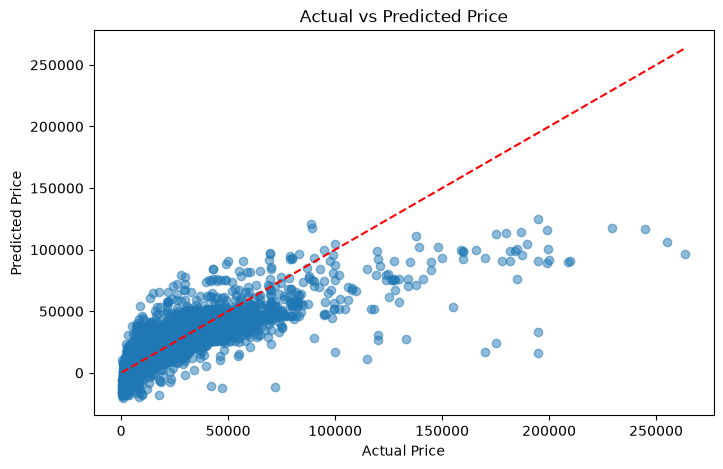

In [162]:
import seaborn as sns

plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)


Text(0.5, 1.0, 'Residual Plot')

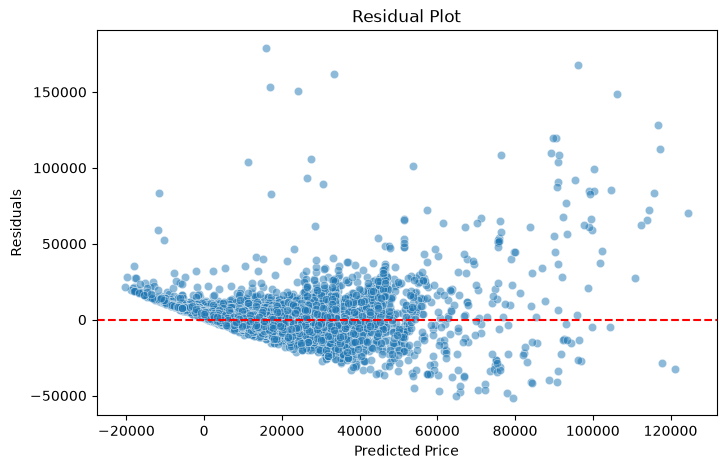

In [163]:
residuals = y_test - y_pred

plt.figure(figsize=(8,5))

sns.scatterplot(x=y_pred, y=residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")


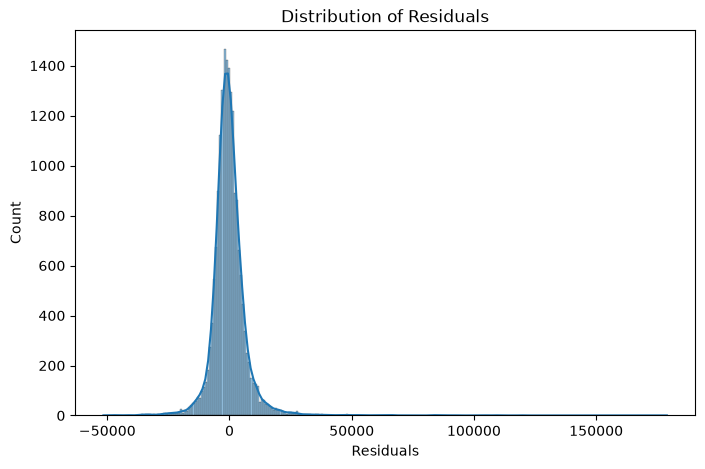

In [164]:
plt.figure(figsize=(8,5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.title("Distribution of Residuals")

plt.show()

In [166]:
print("R2 Score:", r2_score(y_test, y_pred))

print("MAE:", mean_absolute_error(y_test, y_pred))

print("MSE:", mean_squared_error(y_test, y_pred))

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 Score: 0.6781175206271006
MAE: 4703.000470551008
MSE: 71448972.13333802
RMSE: 8452.74938309057


# Solution 2 - include the constant to both Xtrain and XTest

Add the constant to the model 

In [67]:
dv = df["price"]


In [92]:
iv = df[["power", "Year"]]
# iv = df[["power", "Year", "kms", "months_old"]]


In [93]:
x_train, x_test, y_train, y_test = train_test_split(iv,dv, test_size=0.2)

In [94]:
x_train = sm.add_constant(x_train)
x_test = sm.add_constant(x_test)

In [100]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(73904, 3)
(18476, 3)
(73904,)
(18476,)


In [95]:
regressionModel2 = sm.OLS(y_train, x_train)

In [105]:
results2 = regressionModel2.fit()

In [106]:
results2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.597
Model:                            OLS   Adj. R-squared:                  0.597
Method:                 Least Squares   F-statistic:                 5.471e+04
Date:                Fri, 20 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:20:46   Log-Likelihood:            -7.8378e+05
No. Observations:               73904   AIC:                         1.568e+06
Df Residuals:                   73901   BIC:                         1.568e+06
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -2.564e+06   1.52e+04   -168.488      0.000   -2.59e+06   -2.53e+06
power        250.7421      0.845    296.867      0.000     249.087     252.398
Year        1269.9387      7.559    168.001      0.000    1255.123    1284.755
==============================================================================
Omnibus:                   170543.147   Durbin-Watson:                   1.990
Prob(Omnibus):                  0.000   Jarque-Bera (JB):       8596729094.615
Skew:                          21.779   Prob(JB):                         0.00
Kurtosis:                    1673.285   Cond. No.                     8.54e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 8.54e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

# Interpretation of OLS Regression Results (price ~ power + Year)

## Summary
This is a multiple linear regression predicting **price** from **power** and **Year** on 73,904 observations. Both predictors are strong and the model explains about 60% of the variation in price. The residual diagnostics show serious problems: extreme outliers, a heavily skewed price, and a badly scaled Year variable. The coefficients point in the right direction, but the printed standard errors and p-values should not be trusted as they are.

**Fitted equation:**

price = -2,591,000 + 252.56 × power + 1,283.52 × Year

---

## 1. Model information
- **Dep. Variable (price):** The outcome being predicted.
- **Model / Method (OLS / Least Squares):** Chooses the coefficients that minimise the sum of squared errors (actual − predicted)².
- **No. Observations (73,904):** A very large sample, so almost any effect will be statistically significant.
- **Df Model (2):** Two predictors (power, Year), excluding the constant.
- **Df Residuals (73,901):** n − k − 1 = 73,904 − 2 − 1.
- **Covariance Type (nonrobust):** Standard errors assume constant error variance (homoskedasticity). This is unlikely to hold for price data.

## 2. Goodness of fit
- **R-squared = 0.599:** Power and Year together explain about 59.9% of the variance in price. The remaining ~40% comes from factors not in the model (mileage, brand, condition, fuel type, transmission, etc.).
- **Adj. R-squared = 0.599:** Same as R² because 2 predictors against ~74k rows makes the penalty negligible. Neither predictor is redundant.
- **F-statistic = 55,290, Prob (F-statistic) = 0.00:** The null hypothesis that all slope coefficients are zero is decisively rejected. The model as a whole is highly significant.
- **Log-Likelihood = -784,170:** Measures model fit under normal errors. It is only meaningful when comparing models fitted to the same data (higher is better).
- **AIC = 1.568e6, BIC = 1.568e6:** Information criteria that balance fit against complexity. Lower is better. They are only useful for comparing alternative models on the same dataset.

## 3. Coefficients

| Term  | Coef       | Std Err  | t        | P>\|t\| | 95% CI                  |
|-------|------------|----------|----------|---------|-------------------------|
| const | -2,591,000 | 15,300   | -169.15  | 0.000   | [-2,620,000, -2,560,000] |
| power | 252.56     | 0.847    | 298.09   | 0.000   | [250.90, 254.22]        |
| Year  | 1,283.52   | 7.610    | 168.65   | 0.000   | [1,268.61, 1,298.44]    |

- **const (-2,591,000):** The predicted price when power = 0 and Year = 0, which is not meaningful. It is large and negative only because it offsets the Year term (1,283.52 × ~2015 ≈ 2,586,000). It should not be interpreted.
- **power (252.56):** Holding Year constant, each additional unit of power increases predicted price by about 252.56. For example, 100 more units of power gives about 25,256 higher price. It has the largest t-value (298.1), so power is the strongest predictor. The confidence interval is very narrow and excludes zero.
- **Year (1,283.52):** Holding power constant, each newer model year increases predicted price by about 1,283.52. Equivalently, a car loses about 1,283 in value per year of age. For example, a car 10 years newer is predicted to cost about 12,835 more. The confidence interval excludes zero.

**Example prediction:** A car with power = 150 from 2015 gives
-2,591,000 + (252.56 × 150) + (1,283.52 × 2015) ≈ **33,000** (approximate, since the printed constant is rounded).

**Column meanings:**
- coef = estimated effect
- std err = sampling uncertainty of the estimate
- t = coef ÷ std err
- P>|t| = probability of a t this extreme if the true effect were zero
- [0.025, 0.975] = 95% confidence interval

## 4. Residual diagnostics
- **Omnibus = 169,559, Prob(Omnibus) = 0.000:** Residuals are not normally distributed.
- **Skew = 21.47:** Extreme right skew (normal = 0). Some cars are priced far above what the model predicts, such as luxury or high-end vehicles or possible data-entry errors.
- **Kurtosis = 1,637:** Extremely heavy tails (normal = 3). A small number of extreme outliers dominate the residuals. Because OLS squares errors, these few points pull the fitted line strongly.
- **Jarque-Bera = 8.23 billion, Prob(JB) = 0.00:** Confirms strong non-normality of the residuals.
- **Durbin-Watson = 1.992:** Close to 2, so there is no autocorrelation in the residuals. This assumption is satisfied.
- **Cond. No. = 855,000:** Very high, which signals numerical instability or multicollinearity. The cause is mainly scaling: Year values (~1990–2024) are far from zero, so the Year column is almost collinear with the intercept. Using car age (2026 − Year) or a centred year fixes this.

## 5. Practical implications
1. **The coefficient estimates are usable as rough average effects.** With ~74k observations, the slopes are not badly biased by non-normal residuals.
2. **The standard errors, t-values and p-values are unreliable.** Price data is almost certainly heteroskedastic (errors grow with price). Non-robust standard errors are likely too small, which overstates precision.
3. **A linear form is probably the wrong shape.** Car prices tend to rise multiplicatively with power, and depreciation is roughly a percentage per year, not a fixed amount.
4. **Omitted variables are likely biasing the coefficients.** Mileage is correlated with age, so the Year effect partly reflects mileage. Brand is correlated with power, so part of the power effect reflects branding.
5. **Statistical significance is not the same as practical importance.** With n = 73,904, almost any effect gets p ≈ 0. Judge importance from coefficient size and R², not p-values.

## 6. Recommended improvements
- Remove impossible values (price ≤ 0, power ≤ 0) and investigate extreme outliers.
- Model **log(price)** to reduce skew and kurtosis. Coefficients then read as percentage effects.
- Replace Year with **age = 2026 − Year** to fix the condition number.
- Use **heteroskedasticity-robust standard errors** (cov_type="HC3").
- Add more predictors if available: mileage, brand, fuel type, transmission, body type.
- Check residual-vs-fitted and Q–Q plots before and after the changes.

```python
import numpy as np
import statsmodels.formula.api as smf

df = df[(df.price > 0) & (df.power > 0)]
df = df[df.price < df.price.quantile(0.999)]
df["age"] = 2026 - df["Year"]

model = smf.ols("np.log(price) ~ np.log(power) + age", data=df).fit(cov_type="HC3")
print(model.summary())
```

## Conclusion
Higher power and a newer model year both clearly increase price: about **252.56 per unit of power** and about **1,283.52 per year**. Together they explain about **60%** of price variation. However, the extreme skewness (21.47), kurtosis (1,637) and high condition number (855,000) mean the model should be refitted with a log-transformed price, an age variable, robust standard errors and outlier treatment before its results are relied on for inference.

In [107]:
y_pred = results2.predict(x_test)

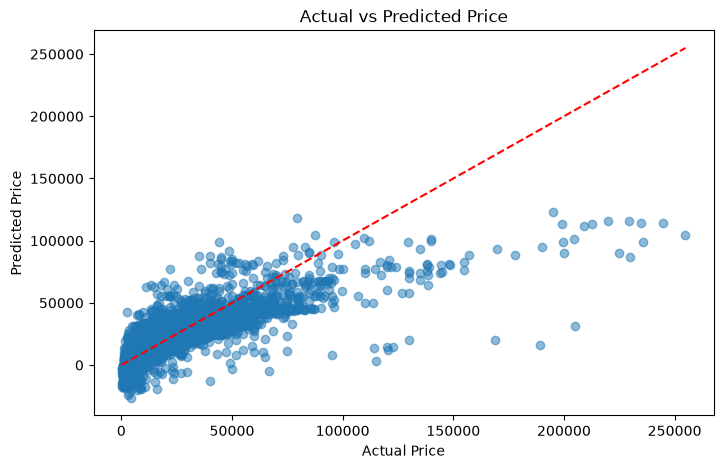

In [109]:
import seaborn as sns

plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)


Text(0.5, 1.0, 'Residual Plot')

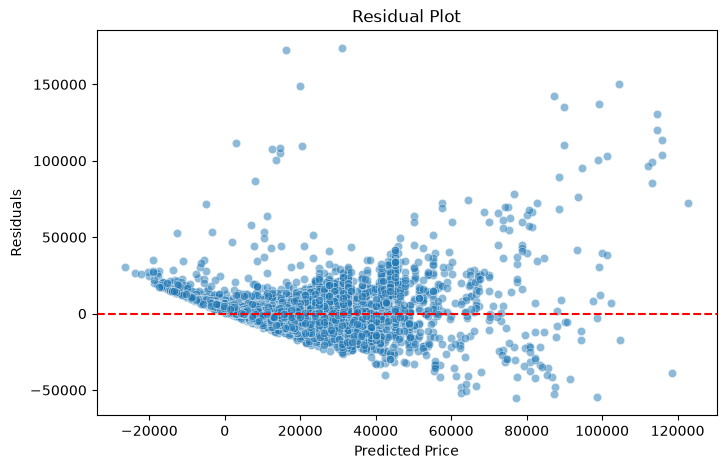

In [110]:
residuals = y_test - y_pred

plt.figure(figsize=(8,5))

sns.scatterplot(x=y_pred, y=residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot")


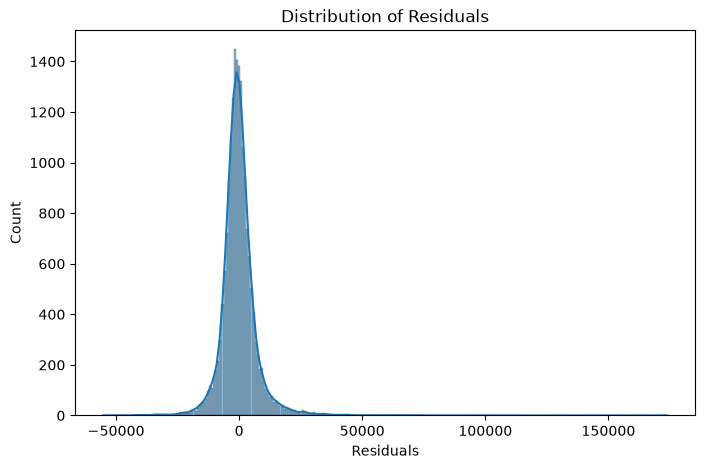

In [111]:
plt.figure(figsize=(8,5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.title("Distribution of Residuals")

plt.show()

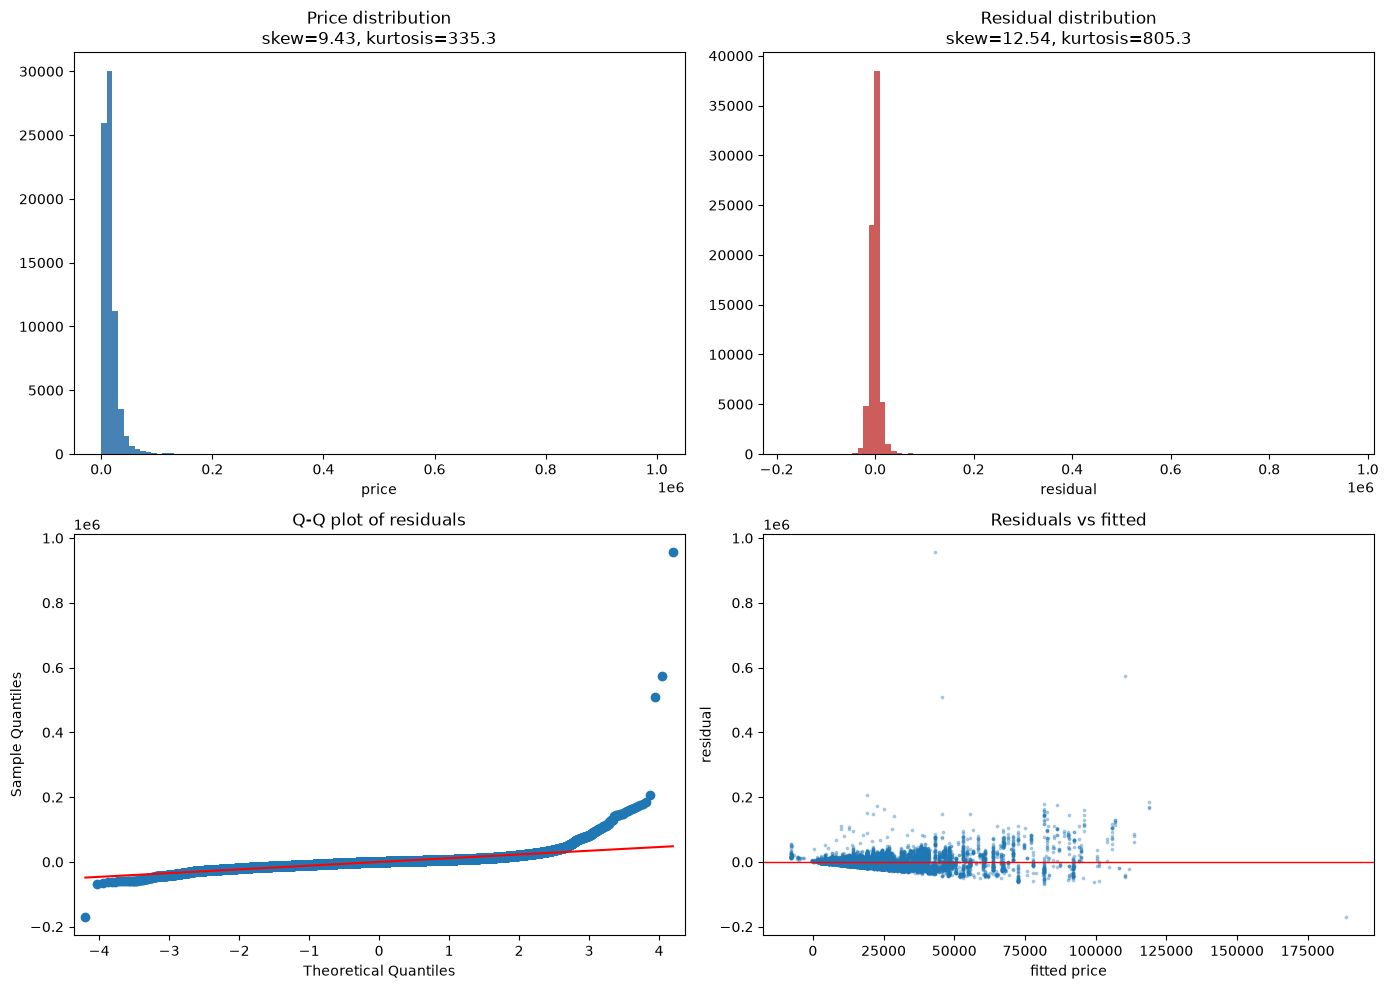

In [112]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import skew, kurtosis

resid  = results.resid
fitted = results.fittedvalues

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# 1. Distribution of price
ax[0, 0].hist(y_train, bins=100, color="steelblue")
ax[0, 0].set_title(f"Price distribution\nskew={skew(y_train):.2f}, "
                   f"kurtosis={kurtosis(y_train, fisher=False):.1f}")
ax[0, 0].set_xlabel("price")

# 2. Distribution of residuals
ax[0, 1].hist(resid, bins=100, color="indianred")
ax[0, 1].set_title(f"Residual distribution\nskew={skew(resid):.2f}, "
                   f"kurtosis={kurtosis(resid, fisher=False):.1f}")
ax[0, 1].set_xlabel("residual")

# 3. Q-Q plot of residuals
sm.qqplot(resid, line="s", ax=ax[1, 0])
ax[1, 0].set_title("Q-Q plot of residuals")

# 4. Residuals vs fitted
ax[1, 1].scatter(fitted, resid, s=3, alpha=0.3)
ax[1, 1].axhline(0, color="red", lw=1)
ax[1, 1].set_title("Residuals vs fitted")
ax[1, 1].set_xlabel("fitted price")
ax[1, 1].set_ylabel("residual")

plt.tight_layout()
plt.show()

# Solution 3 - include the catagorical variables

Add the constant to the model 

In [114]:
df.columns

Index(['Index', 'ID', 'make', 'model', 'months_old', 'power', 'gear',
       'fuel_type', 'kms', 'price', 'Year'],
      dtype='str')

In [115]:
df.head()

,Index,ID,make,model,months_old,power,gear,fuel_type,kms,price,Year
0,0,97860,Porsche,911,240,210,manual,gasoline,202000,999999,1998
1,1,27821,Ford,Mustang,54,487,manual,gasoline,30000,685000,2013
2,2,97801,Porsche,911,358,220,manual,gasoline,56300,555555,1988
8,8,62403,Bentley,Continental,5,522,automatic,gasoline,1200,302900,2017
9,9,62402,Bentley,Continental,14,522,automatic,gasoline,17900,289700,2016


In [122]:
# Make the dummy variables

In [121]:
df.make.value_counts()

make
Bmw              10546
Audi              9368
Volkswagen        8749
Renault           6379
Opel              6136
Ford              5839
Citroen           5689
Mercedes-Benz     5591
Peugeot           5273
Seat              4900
Toyota            3067
Fiat              2830
Nissan            2764
Hyundai           2013
Volvo             1958
Land              1523
Porsche           1413
Kia               1185
Skoda             1052
Honda              802
Jeep               690
Smart              682
Mazda              611
Alfa               402
Mitsubishi         394
Chevrolet          389
Ds                 348
Mini               317
Jaguar             278
Ssangyong          269
Chrysler           236
Dacia              196
Saab               156
Bentley            116
Suzuki             110
Iveco              109
Name: count, dtype: int64